# 01 · Data: what exists, what we have, what the simulator makes

**Ground rule:** train only on simulated audio (TTS + recorded ambience + rooms). Real
recordings are test-only and measure how well the simulator predicts reality. The better
that match, the more we can trust the simulator for everything.

Notebooks in this series:
1. data (this one)
2. hardware budget, architectures, state of the art
3. training curves
4. results: what 16 tiles buy

In [1]:
import numpy as np
from IPython.display import Audio, display

from nbutil import ROOT


def du(path):
    p = ROOT / path
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e9 if p.exists() else float("nan")

## 1. Downloaded (all under `data/raw/`, git-ignored)

In [2]:
inventory = [
    ("data/raw/speech_commands", "Google Speech Commands v2: 105k one-word clips, 35 words, ~2.6k speakers", "29 h", "TEST: real positives for the 12 SC control words"),
    ("data/raw/mswc", "Multilingual Spoken Words (Common Voice), English, only our 66 candidate words", "65k clips, 18 h", "TEST: real positives (≤1500 per word)"),
    ("data/raw/ami", "AMI meeting corpus, far-field array mic 1, all 152 meetings", "86 h", "TEST: real conversation false-alarm stream"),
    ("data/raw/librispeech_test", "LibriSpeech test-clean + dev-clean (read audiobooks)", "10.8 h", "TEST: real read speech in real rooms"),
    ("data/raw/librispeech_dev", "  (dev half of the above)", "", ""),
    ("data/raw/musan", "MUSAN: music, noise, speech", "~100 h", "music/noise: ambience (train+test split); speech: TEST babble only"),
    ("data/raw/demand", "DEMAND: multichannel environment noise (kitchen, car, street, cafe...)", "~1.5 h", "ambience (split by file)"),
    ("data/raw/esc50", "ESC-50: 2000 environmental sound clips, 50 classes", "2.8 h", "ambience (split by file)"),
    ("data/raw/rirs_noises", "OpenSLR-28: simulated + real room impulse responses", "60k RIRs", "simulated: train/sim-test; real: TEST"),
    ("data/raw/text", "Switchboard transcripts, OpenSubtitles (first 400 MB), DailyDialog", "338k utterances", "TRAIN text for TTS conversation"),
]
print(f"{'path':28s} {'GB':>6s}  {'size':16s} role")
for path, what, size, role in inventory:
    print(f"{path:28s} {du(path):6.1f}  {size:16s} {role}\n{'':54s}{what}")

path                             GB  size             role


data/raw/speech_commands        3.3  29 h             TEST: real positives for the 12 SC control words
                                                      Google Speech Commands v2: 105k one-word clips, 35 words, ~2.6k speakers


data/raw/mswc                   0.7  65k clips, 18 h  TEST: real positives (≤1500 per word)
                                                      Multilingual Spoken Words (Common Voice), English, only our 66 candidate words
data/raw/ami                   10.0  86 h             TEST: real conversation false-alarm stream
                                                      AMI meeting corpus, far-field array mic 1, all 152 meetings
data/raw/librispeech_test       0.4  10.8 h           TEST: real read speech in real rooms
                                                      LibriSpeech test-clean + dev-clean (read audiobooks)
data/raw/librispeech_dev        0.4                   
                                                        (dev half of the above)
data/raw/musan                 12.6  ~100 h           music/noise: ambience (train+test split); speech: TEST babble only
                                                      MUSAN: music, noise, speech
data/raw/demand             

data/raw/rirs_noises            3.8  60k RIRs         simulated: train/sim-test; real: TEST
                                                      OpenSLR-28: simulated + real room impulse responses
data/raw/text                   1.6  338k utterances  TRAIN text for TTS conversation
                                                      Switchboard transcripts, OpenSubtitles (first 400 MB), DailyDialog


## 2. Generated by the simulator

| what | size | how |
|---|---|---|
| TTS keyword clips, 66 candidates | ~2,000 train + ~500 test per word | Piper TTS, 4 voice models ≈ 1,100 speakers; test = held-out speakers; random rate, pitch noise, punctuation |
| TTS near-misses | up to 40 phrases per word | CMUdict 1-phoneme edits ("telescope" → "telescopes", ...) |
| TTS partial phrases | 30k | fragments sharing syllables with candidates |
| TTS conversation | 100k train (77 h) + 15k test (12 h) utterances | text from Switchboard 50% / OpenSubtitles 35% / DailyDialog 15%, so word frequencies follow real speech |
| mixing (`model/mix.py`) | on the fly | see below |
| training cache | 2.5M windows × 1.6 s, 4 GB | 16 fresh mixes per keyword clip, 8 per near-miss |
| test streams | 19 h sim + 106 h real | `model/build_stream.py` |

**What the mixer does:**
* 1–3 talkers with turn-taking and overlaps, sometimes crowd babble;
* ambience at 0–35 dB SNR;
* each talker at 0.3–5 m: the room response split into direct + reverberant parts,
  duller with distance, 15% "muffled" (pocket, next room);
* ±10% speed;
* overall level −55 to −12 dBFS.

In [3]:
for k in ("synth", "synth_near", "synth_neg", "synth_convo", "cache/train", "cache/test"):
    print(f"data/{k:14s} {du('data/' + k):6.1f} GB")
for s in ("sim_convo", "sim_hard", "real_ami", "real_read"):
    p = ROOT / "data/cache" / f"stream_{s}" / "chunk.npy"
    if p.exists():
        print(f"stream {s:10s} {int(np.load(p)[-1]) * 0.016 / 3600:6.1f} h")

data/synth             9.5 GB
data/synth_near        0.8 GB
data/synth_neg         0.9 GB
data/synth_convo      10.2 GB
data/cache/train       4.1 GB
data/cache/test        0.2 GB
stream sim_convo    15.0 h
stream sim_hard      4.2 h
stream real_ami     86.4 h
stream real_read    19.9 h


## 3. Listen: simulator vs real

The same words at 0.5 / 2 / 4.5 m, with people talking before them. The keyword ends at
4.0 s in each scene. "sim" is a TTS voice in a simulated room; "real" is a Common Voice
speaker placed in a *recorded* room. More files are in `data/examples/INDEX.md`.

In [4]:
ex = ROOT / "data/examples"
for word in ("telescope", "alchemist"):
    for kind in ("sim", "real"):
        for f in sorted((ex / kind).glob(f"keyword_{word}_d*.wav")):
            print(f"{kind:4s} {f.stem}")
            display(Audio(str(f)))
print("real conversation (AMI meeting) vs simulated conversation:")
for f in sorted((ex / "real").glob("ami_meeting_*.wav"))[:1] + sorted((ex / "sim").glob("conversation_*.wav"))[:1]:
    print(f.stem)
    display(Audio(str(f)))

(audio players removed from the committed copy: run this cell locally to listen)


## 4. What the chip sees

The 16 log-band features (the chip's filterbank output, uint8 codes, 1/8 octave per step)
for one simulated and one real keyword scene. These codes are all the classifier ever gets.

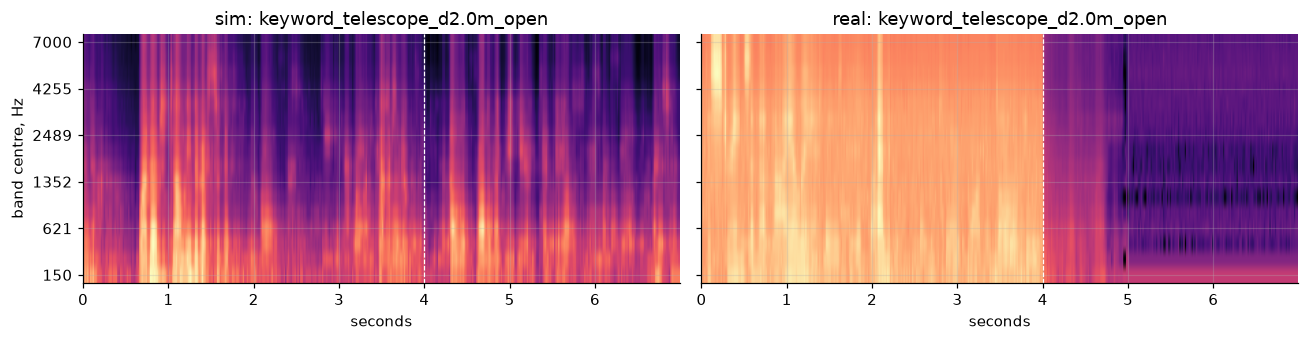

In [5]:
import matplotlib.pyplot as plt
import soundfile as sf

from features import features
from frontend import band_centers

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, kind in zip(axes, ("sim", "real")):
    f = sorted((ex / kind).glob("keyword_telescope_d2.0m_*.wav"))[0]
    x, _ = sf.read(str(f), dtype="float32")
    F = features(x)
    ax.imshow(F.T, aspect="auto", origin="lower", cmap="magma", extent=[0, len(F) * 0.016, 0, 16])
    ax.set(title=f"{kind}: {f.stem}", xlabel="seconds")
    ax.axvline(4.0, color="w", lw=0.8, ls="--")
axes[0].set_yticks(np.arange(0.5, 16, 3), [f"{c:.0f}" for c in band_centers()[::3]])
axes[0].set_ylabel("band centre, Hz")
plt.tight_layout()

## 5. Not downloaded yet (candidates)

| dataset | why it would help | catch |
|---|---|---|
| **VOiCES** (SRI / Lab41) | LibriSpeech played through speakers and **re-recorded at many distances in real rooms**: a direct test of our distance/room model | ~20+ GB |
| **CHiME-5/6** | real dinner-party conversation in homes, far-field: the best match for "device in a kitchen" false alarms | signed licence |
| Common Voice, full English | thousands more real speakers for any word | 80+ GB; we have the per-word cut (MSWC) |
| BUT ReverbDB, ACE, MIT IR survey | more **real** room impulse responses for the test side | small |
| DNS Challenge noise, FSD50K | more varied ambience | large |
| GigaSpeech / People's Speech | huge amounts of real conversational speech for false-alarm tests | very large |

## 6. Our own recordings (setting up)

`hw/pi_mics/`: two PDM mics on a Raspberry Pi 5, clocked at the chip's 1.024 MHz and
decimated with the chip's own CIC (bit-exact, `hw/pi_mics/test_pdm.py`). Recording runs
always-on. This will give:

* **E1:** real false alarms/h in the actual environment, the most important test stream;
* **E2:** labelled real keywords and near-misses at known distances (`label.py`);
* **E0, E3:** a mic-match check, and the speaker-in-room test of the distance model
  (`hw/pi_speaker/`).

Once that data arrives it goes in here as new test streams (`real_home`, `real_labelled`).